# CSC 583 Natural Language Processing - Homework #3: Vector Embeddings and RAG

**Name:** Asad Khan
**Course:** CSC 583 (Fall 2026)
**Assignment:** HW #3 - Vector Embeddings and RAG
**Collaborators:** None. GenAI disclosure: Claude (Anthropic) was used as a coding assistant, to help with the manual scoring, and to draft the write-up.

## CSC 583 HW\#3: Vector Embeddings and RAG (2026)

Vector Embeddings and RAG Starter Code
Multi-Document RAG System for AI Policy Analysis

In [1]:
# -*- coding: utf-8 -*-
# Setup
# ----------------------------
# Installs only on Google Colab; locally the packages come from the uv environment
# (see NLP/pyproject.toml).
import sys
if "google.colab" in sys.modules:
    !pip install -qU uv
    !uv pip install --system -q \
        "langchain==1.3.14" \
        "langchain-community==0.4.1" \
        "langchain-openai==1.5.1" \
        "langchain-chroma==1.1.0" \
        "langchain-huggingface==1.2.2" \
        "chromadb==1.5.9" \
        "sentence-transformers==5.7.0" \
        "tiktoken" "openai" "pypdf" "python-dotenv" "requests>=2.32.5,<3.0.0"

In [2]:
# Imports
# ----------------------------
import os, re, shutil, json, hashlib, warnings
import requests
import chromadb
from typing import List, Dict, Tuple
from IPython.display import Markdown, display

# LangChain imports
from langchain_core.documents import Document
from langchain_community.document_loaders import PyPDFLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import ChatOpenAI, OpenAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

warnings.filterwarnings("ignore", category=DeprecationWarning)

/var/folders/51/c247q47s2d38qy58zlgccks00000gn/T/ipykernel_56675/894715360.py:11: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader, TextLoader


## Part 1: Define Core Functions

In [3]:
# Short, human-readable names for each file. They go into every chunk's metadata
# and are shown to the LLM so it can cite where a fact came from.
DOC_TITLES = {
    "Blueprint-for-an-AI-Bill-of-Rights.pdf": "Blueprint for an AI Bill of Rights (2022)",
    "2023-24283.pdf": "Executive Order 14110 on Safe, Secure, and Trustworthy AI (2023)",
    "NIST.AI.100-1.pdf": "NIST AI Risk Management Framework (AI RMF 1.0)",
    "cellar_e0649735-a372-11eb-9585-01aa75ed71a1.0001.02_DOC_1.pdf": "EU Artificial Intelligence Act (2021 proposal)",
}
DOC_SHORT = {
    "Blueprint-for-an-AI-Bill-of-Rights.pdf": "Blueprint",
    "2023-24283.pdf": "EO 14110",
    "NIST.AI.100-1.pdf": "NIST AI RMF",
    "cellar_e0649735-a372-11eb-9585-01aa75ed71a1.0001.02_DOC_1.pdf": "EU AI Act",
}

# Default parameter values (Experiment A)
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 200
TOP_K = 4

In [4]:
# 1-1: Load and preprocess documents
# ----------------------------
def load_documents() -> List[Document]:
    """
    Load the four AI policy documents from their URLs.
    Returns a list of Document objects.
    """
    # (1) TODO: Implement this function
    # Load all four documents using appropriate LangChain document loaders
    # Handle both PDF and text documents
    # Return a list of Document objects
    url = "https://raw.githubusercontent.com/ntomuro/CSC583_2026Fall/main/HW3/data"
    document_filenames = [
        "Blueprint-for-an-AI-Bill-of-Rights.pdf", # The White House "Blueprint for an AI Bill of Rights" (2022)
        "2023-24283.pdf", # Executive Order on the Safe, Secure, and Trustworthy Development and Use of Artificial Intelligence (2023)
        "NIST.AI.100-1.pdf", # NIST AI Risk Management Framework (AI RMF 1.0) Overview
        "cellar_e0649735-a372-11eb-9585-01aa75ed71a1.0001.02_DOC_1.pdf" # The EU Artificial Intelligence Act (Key Principles Summary)
    ]
    ## Continue the TODO and collect raw documents in a variable 'documents'
    ## and return it.  You'll use langchain's PyPDFLoader, TextLoader to do.
    data_dir = "data"
    os.makedirs(data_dir, exist_ok=True)

    documents = []
    for filename in document_filenames:
        path = os.path.join(data_dir, filename)
        # Use the local copy when present, otherwise download it from the course repo
        if not os.path.exists(path):
            response = requests.get(f"{url}/{filename}", timeout=60)
            response.raise_for_status()
            with open(path, "wb") as f:
                f.write(response.content)

        loader = PyPDFLoader(path) if filename.lower().endswith(".pdf") else TextLoader(path, encoding="utf-8")
        pages = loader.load()  # one Document per PDF page

        for page in pages:
            page.metadata["source_file"] = filename
            page.metadata["source_title"] = DOC_TITLES[filename]
            page.metadata["doc_short"] = DOC_SHORT[filename]
            page.metadata["page_number"] = page.metadata.get("page", 0) + 1
        documents.extend(pages)
        print(f"  {DOC_SHORT[filename]:<12} {len(pages):>4} pages  {sum(len(p.page_content) for p in pages):>8,} chars")

    return documents


def clean_text(text: str) -> str:
    """Repair common PDF extraction artifacts before splitting."""
    # Running headers/footers that carry no content
    text = re.sub(r"\d{5} Federal Register / Vol\. 88, No\. 210 / Wednesday, November 1, 2023 / (Presidential Documents|Rules and Regulations)", " ", text)
    text = re.sub(r"VerDate Sep<11>2014.*?(\n|$)", " ", text)
    text = re.sub(r"\bEN \d+ +EN\b", " ", text)
    text = re.sub(r"^\s*SECTION TITLE\s*", " ", text)
    # Words hyphenated across a line break: "respon-\nsible" -> "responsible"
    text = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", text)
    # PDF lines are visual, not paragraphs: join them into running text
    text = re.sub(r"\s*\n\s*", " ", text)
    text = re.sub(r"[ \t]{2,}", " ", text)
    return text.strip()


def preprocess_documents(documents: List[Document],
                         chunk_size: int = CHUNK_SIZE,
                         chunk_overlap: int = CHUNK_OVERLAP) -> List[Document]:
    """
    Split documents into chunks for vector storage.
    """
    # (2) TODO: Implement text splitting
    # Use RecursiveCharacterTextSplitter with appropriate parameters
    # Consider what chunk_size and chunk_overlap work best for multi-document retrieval
    # Return list of document chunks
    cleaned = [Document(page_content=clean_text(d.page_content), metadata=dict(d.metadata))
               for d in documents]

    # Prefer to cut at sentence and clause boundaries; keep the period with its sentence
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=["\n\n", "\n", ". ", "; ", ", ", " ", ""],
        keep_separator="end",
        add_start_index=True,
    )
    chunks = text_splitter.split_documents(cleaned)

    # Drop near-empty chunks (cover pages, page-number-only fragments)
    chunks = [c for c in chunks if len(c.page_content) >= 100]
    for i, c in enumerate(chunks):
        c.metadata["chunk_id"] = i

    return chunks

In [5]:
# 1-2: Vector Store Population
# ----------------------------
_embedding_cache = {}

def get_embeddings(embedding_model_name: str) -> HuggingFaceEmbeddings:
    """Load each sentence transformer once and reuse it across experiments."""
    if embedding_model_name not in _embedding_cache:
        _embedding_cache[embedding_model_name] = HuggingFaceEmbeddings(
            model_name=f"sentence-transformers/{embedding_model_name}",
            encode_kwargs={"normalize_embeddings": True},
        )
    return _embedding_cache[embedding_model_name]


def create_vector_store(documents: List[Document], embedding_model_name: str, client,
                        k: int = TOP_K, collection_name: str = "ai_policy"):
    """
    Create and return a retriever from documents using the specified embedding model.
    """
    # (3) TODO: Implement vector store creation
    # Initialize embedding function with the specified model
    # Create Chroma vector store from documents
    # Return a 'retriever' with search_kwargs={"k": 4}
    embeddings = get_embeddings(embedding_model_name)

    # Start from an empty collection so re-running the notebook does not add duplicates
    try:
        client.delete_collection(collection_name)
    except Exception:
        pass

    vector_store = Chroma.from_documents(
        documents=documents,
        embedding=embeddings,
        client=client,
        collection_name=collection_name,
        collection_metadata={"hnsw:space": "cosine"},  # cosine distance on unit vectors
    )
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": k})

    return retriever

In [6]:
# 1-3: Query & Evaluation Set
# ----------------------------
def create_test_queries() -> List[str]:
    """
    Create a diverse set of 5 test queries as specified in the assignment.
    """
    # (4) TODO: Implement this function to return 5 well-designed test queries
    # Include:
    # Q1 Single-Document Factual (Document A)
    # Q2 Single-Document Factual (Document B -- a different document than Q1)
    # Q3 Multi-Document Synthesis (Search & Combine + Thematic Synthesis, combined)
    # Q4 Comparative
    # Q5 Specific Definition/Scope
    # You can hard-code your own queries, or automatically generate queries in some way.
    queries = [
        # Q1 Single-document factual: Blueprint for an AI Bill of Rights
        "Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' "
        "principle, when should people be able to opt out of an automated system, what must a fallback "
        "and escalation process provide, and which sensitive domains call for extra human oversight?",

        # Q2 Single-document factual: Executive Order 14110
        "Under Executive Order 14110, what must companies developing dual-use foundation models report "
        "to the federal government, and what computing-power thresholds trigger these reporting "
        "requirements for models and for computing clusters?",

        # Q3 Multi-document synthesis (search & combine + thematic synthesis)
        "What transparency and explanation duties do the Blueprint for an AI Bill of Rights, the EU AI Act, "
        "and the NIST AI RMF each place on those who build or deploy AI systems, and what common "
        "understanding of why transparency matters emerges across them?",

        # Q4 Comparative
        "How does the NIST AI RMF's voluntary approach to managing AI risk differ from the EU AI Act's "
        "legally binding obligations for high-risk AI systems, in terms of who must comply, how risk is "
        "assessed, and what happens before a system can be deployed?",

        # Q5 Specific definition / scope
        "How does the EU AI Act proposal define an 'AI system', and under Article 6, what conditions make "
        "an AI system 'high-risk'?",
    ]
    return queries


# Which document(s) a good retrieval should hit, used only as a supporting
# diagnostic (the official scores are my manual 1-3 judgments).
EXPECTED_SOURCES = [
    {"Blueprint"},
    {"EO 14110"},
    {"Blueprint", "EU AI Act", "NIST AI RMF"},
    {"NIST AI RMF", "EU AI Act"},
    {"EU AI Act"},
]

In [7]:
# 1-4: The RAG Chain
# ----------------------------
LLM_MODEL = "gpt-4o-mini"

RAG_PROMPT = PromptTemplate.from_template(
"""You are a careful AI-policy analyst. Answer the question using ONLY the context excerpts below.
Each excerpt is labeled with the document it came from and its page number.

Rules:
- Use only facts stated in the context. Do not add knowledge from outside it.
- Cite the supporting excerpt after each claim, e.g. [Blueprint, p. 46].
- If the question asks about several documents, cover each one separately and then synthesize.
- If the context does not cover part of the question (for example, a document is missing), say so explicitly.

Context:
{context}

Question: {question}

Answer:"""
)

# Answers are cached on disk so that re-running the notebook reproduces exactly the
# outputs I scored by hand (temperature 0 is close to, but not fully, deterministic).
ANSWER_CACHE_PATH = "rag_answer_cache.json"
try:
    with open(ANSWER_CACHE_PATH, encoding="utf-8") as f:
        _answer_cache = json.load(f)
except FileNotFoundError:
    _answer_cache = {}

_llm = None

def format_context(docs: List[Document]) -> str:
    return "\n\n".join(
        f"[Excerpt {i}] ({d.metadata['doc_short']}, p. {d.metadata['page_number']})\n{d.page_content}"
        for i, d in enumerate(docs, 1)
    )


def run_rag_query(query: str, retriever) -> Tuple[str, List[Document]]:
    """
    Execute a RAG query: retrieve relevant context and generate an answer.
    Returns the generated answer and the retrieved documents for evaluation.
    """
    # (5) TODO: Implement the RAG query execution
    # Retrieve relevant chunks using the retriever
    # Construct a high-quality prompt that includes context and query
    # Use an LLM chain to generate the answer
    # Assign the answer and retrieved documents to variables 'answer' and
    # 'retrieved_docs', and return them.
    global _llm
    retrieved_docs = retriever.invoke(query)
    context = format_context(retrieved_docs)

    key = hashlib.sha256(f"{LLM_MODEL}\n{context}\n{query}".encode("utf-8")).hexdigest()
    if key in _answer_cache:
        answer = _answer_cache[key]
    else:
        if _llm is None:
            _llm = ChatOpenAI(model=LLM_MODEL, temperature=0, seed=42)
        chain = RAG_PROMPT | _llm | StrOutputParser()
        answer = chain.invoke({"context": context, "question": query})
        _answer_cache[key] = answer
        with open(ANSWER_CACHE_PATH, "w", encoding="utf-8") as f:
            json.dump(_answer_cache, f, indent=1, ensure_ascii=False)

    return answer, retrieved_docs

In [8]:
# 1-5: Evaluation
# ----------------------------
# The starter code asks for scores with input(). I inspected every run's retrieved
# chunks and answer (printed below each run) and recorded my manual scores here, so
# the notebook can be re-run end to end. Key: (run label, query number) -> (retrieval, answer).
# Set INTERACTIVE_EVAL = True to be prompted for any missing score instead.
INTERACTIVE_EVAL = False
MANUAL_SCORES = {}  # filled in the "Manual scores" cell below
CURRENT_RUN = None
SHOW_FULL_CHUNKS = False

def describe_retrieval(retrieved_docs: List[Document], width: int = 160) -> None:
    for i, d in enumerate(retrieved_docs, 1):
        text = d.page_content if SHOW_FULL_CHUNKS else d.page_content[:width].replace("\n", " ") + "..."
        print(f"   [{i}] {d.metadata['doc_short']:<12} p.{d.metadata['page_number']:<4} {text}")


def source_coverage(query_index: int, retrieved_docs: List[Document]) -> float:
    """Fraction of the expected documents that appear among the retrieved chunks."""
    expected = EXPECTED_SOURCES[query_index]
    found = {d.metadata["doc_short"] for d in retrieved_docs}
    return len(expected & found) / len(expected)


def evaluate_results(query: str, retrieved_docs: List[Document], answer: str) -> Tuple[int, int]:
    """
    Manually evaluate the retrieval quality and answer quality.
    Returns (retrieval_score, answer_score) on scale 1-3.
    """
    # Manually evaluate and return scores
    # Retrieval Score: 1=Irrelevant, 2=Partially relevant, 3=Highly relevant
    # Answer Score: 1=Incorrect, 2=Partially correct, 3=Correct and comprehensive
    print(f"Query: {query}")
    print(f"Retrieved {len(retrieved_docs)} documents")
    describe_retrieval(retrieved_docs)
    print(f"Answer: {answer}")
    print("---")

    q_num = create_test_queries().index(query) + 1
    if (CURRENT_RUN, q_num) in MANUAL_SCORES:
        retrieval_score, answer_score = MANUAL_SCORES[(CURRENT_RUN, q_num)]
    elif INTERACTIVE_EVAL:
        retrieval_score = int(input("Retrieval score (1-3): "))
        answer_score = int(input("Answer score (1-3): "))
    else:
        retrieval_score, answer_score = None, None
    print(f"Manual scores -> retrieval: {retrieval_score}, answer: {answer_score}")

    return retrieval_score, answer_score

### Manual scores

Every score below was assigned after reading the retrieved chunks and the generated answer printed in Parts 3 and 4. The rubric is the one from the assignment: retrieval 1 = irrelevant, 2 = partially relevant (or misses a required document), 3 = highly relevant and from the right document(s); answer 1 = incorrect / missing key points, 2 = partially correct, 3 = correct and comprehensive. The justification for each score is in the write-up.

In [9]:
MANUAL_SCORES.update({
    # Experiment A (chunk_size 1000, overlap 200, k 4)          Q: (retrieval, answer)
    **{("all-MiniLM-L6-v2", q): s for q, s in
       {1: (2, 2), 2: (3, 2), 3: (2, 1), 4: (2, 1), 5: (2, 2)}.items()},
    **{("all-mpnet-base-v2", q): s for q, s in
       {1: (2, 2), 2: (2, 2), 3: (2, 2), 4: (3, 2), 5: (2, 2)}.items()},
    # Experiment B (all-MiniLM-L6-v2, one parameter changed at a time)
    **{("B:size=250 (overlap=50)", q): s for q, s in
       {1: (2, 1), 2: (2, 1), 3: (2, 1), 4: (1, 1), 5: (1, 1)}.items()},
    **{("B:size=500", q): s for q, s in
       {1: (2, 2), 2: (2, 2), 3: (2, 2), 4: (2, 1), 5: (1, 1)}.items()},
    **{("B:size=2000", q): s for q, s in
       {1: (3, 3), 2: (3, 3), 3: (1, 1), 4: (2, 1), 5: (2, 2)}.items()},
    **{("B:overlap=0", q): s for q, s in
       {1: (2, 2), 2: (3, 2), 3: (2, 2), 4: (2, 1), 5: (2, 2)}.items()},
    **{("B:overlap=100", q): s for q, s in
       {1: (2, 2), 2: (3, 2), 3: (2, 2), 4: (2, 1), 5: (2, 2)}.items()},
    **{("B:overlap=400", q): s for q, s in
       {1: (2, 2), 2: (3, 2), 3: (2, 1), 4: (2, 1), 5: (2, 2)}.items()},
    **{("B:k=2", q): s for q, s in
       {1: (2, 2), 2: (3, 2), 3: (2, 1), 4: (2, 1), 5: (2, 1)}.items()},
    **{("B:k=8", q): s for q, s in
       {1: (3, 3), 2: (3, 2), 3: (2, 1), 4: (2, 1), 5: (2, 2)}.items()},
    **{("B:k=12", q): s for q, s in
       {1: (3, 3), 2: (2, 2), 3: (2, 2), 4: (2, 2), 5: (2, 1)}.items()},
})

## Part 2: Experiment (main())

In [10]:
# 2: The Main Experiment
# ----------------------------
def safe_name(s):
    """
    Convert a string to a valid file name by removing invalid characters
    and using underscores to separate words.
    """
    return re.sub(r'[^0-9A-Za-z._-]', '_', s)


def setup_api_keys():
    # (6) TODO: Set your OpenAI and HuggingFace API keys
    # On Colab the keys come from userdata; locally they come from NLP/.env (git-ignored).
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
        os.environ["HUGGINGFACE_HUB_TOKEN"] = userdata.get("HUGGINGFACE_HUB_TOKEN")
    except ImportError:
        from dotenv import load_dotenv
        load_dotenv("../.env")
    assert os.environ.get("OPENAI_API_KEY"), "OPENAI_API_KEY is not set"


def run_queries(retriever, test_queries, run_label):
    """Run every query through one retriever and collect scores and details."""
    global CURRENT_RUN
    CURRENT_RUN = run_label
    run_results = {'retrieval_scores': [], 'answer_scores': [], 'coverage': [], 'details': []}

    for i, query in enumerate(test_queries):
        print(f"\n[{run_label}] Query {i+1}: {query}")

        # Run RAG query
        answer, retrieved_docs = run_rag_query(query, retriever)

        # Evaluate results
        retrieval_score, answer_score = evaluate_results(query, retrieved_docs, answer)

        # Store scores
        run_results['retrieval_scores'].append(retrieval_score)
        run_results['answer_scores'].append(answer_score)
        run_results['coverage'].append(source_coverage(i, retrieved_docs))
        run_results['details'].append({
            'query': query,
            'answer': answer,
            'retrieved_docs': retrieved_docs
        })

    # Calculate averages (skipping any run that has not been scored yet)
    def avg(xs):
        xs = [x for x in xs if x is not None]
        return sum(xs) / len(xs) if xs else float("nan")
    run_results['avg_retrieval'] = avg(run_results['retrieval_scores'])
    run_results['avg_answer'] = avg(run_results['answer_scores'])
    run_results['avg_coverage'] = avg(run_results['coverage'])
    return run_results


def main():
    """
    Main function to run the complete RAG experiment.
    """
    setup_api_keys()

    # Define embedding models to test
    embedding_models = [
        "all-MiniLM-L6-v2",  # 384
        "all-mpnet-base-v2", # 768
    ]

    # Load and preprocess documents
    print("Loading documents...")
    raw_documents = load_documents()
    print(f"Loaded {len(raw_documents)} raw documents")

    print("Preprocessing documents...")
    processed_documents = preprocess_documents(raw_documents)
    print(f"Created {len(processed_documents)} document chunks")

    # Create test queries
    test_queries = create_test_queries()
    print(f"Created {len(test_queries)} test queries")

    # Store results for analysis
    results = {}

    # Run experiment for each embedding model
    for model_name in embedding_models:
        print(f"\n{'='*50}")
        print(f"Testing model: {model_name}")
        print(f"{'='*50}")

        # Create a unique DB for the embedding model
        model_key = safe_name(model_name)
        db_path = f"./chroma_db_{model_key}"   # unique per model

        chroma_client = chromadb.PersistentClient(path=db_path)

        # Create vector store with current model
        retriever = create_vector_store(processed_documents, model_name, chroma_client)

        model_results = run_queries(retriever, test_queries, run_label=model_name)
        results[model_name] = model_results

        print(f"\nModel {model_name} - Avg Retrieval: {model_results['avg_retrieval']:.2f}, Avg Answer: {model_results['avg_answer']:.2f}")

    return results, raw_documents, processed_documents, test_queries

## Part 3: Run Experiment

In [11]:
# Execute the experiment (full chunk text is printed so every retrieval can be inspected)
SHOW_FULL_CHUNKS = True
final_results, raw_documents, documents, queries = main()

Loading documents...


  Blueprint      73 pages   220,968 chars


  EO 14110       36 pages   145,506 chars


  NIST AI RMF    48 pages   106,444 chars


  EU AI Act     108 pages   314,714 chars
Loaded 265 raw documents
Preprocessing documents...
Created 1065 document chunks
Created 5 test queries

Testing model: all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


[all-MiniLM-L6-v2] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remedy problems you encounter. You should be able to opt out from automated systems in favor of a human alternative, where appropriate. Appropriateness should be determined based on reasonable exp

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


[all-mpnet-base-v2] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.7    Human consideration and fallback should be accessible, equitable, effective, maintained, accompanied by appropriate operator training, and should not impose an unreasonable burden on the public. Automated systems with an intended use within sensi - tive domains, including, but not limited to, criminal justice, employment, education, and health, sho

### Print Results

In [12]:
# Analysis Helper Functions
# ----------------------------

def print_results_table(results: Dict):
    """Print a formatted results table for the report."""
    print("\n" + "="*72)
    print("EXPERIMENT RESULTS SUMMARY")
    print("="*72)
    print(f"{'Model':<25} {'Avg Retrieval':<15} {'Avg Answer':<15} {'Doc coverage':<15}")
    print("-"*72)

    for model_name, model_results in results.items():
        print(f"{model_name:<25} {model_results['avg_retrieval']:<15.2f} {model_results['avg_answer']:<15.2f} {model_results['avg_coverage']:<15.2f}")

def compare_retrieval_for_query(results: Dict, query_index: int):
    """Compare retrieval performance for a specific query across models."""
    print(f"\nRetrieval comparison for Query {query_index + 1}:")
    for model_name, model_results in results.items():
        retrieval_score = model_results['retrieval_scores'][query_index]
        answer_score = model_results['answer_scores'][query_index]
        sources = [f"{d.metadata['doc_short']} p.{d.metadata['page_number']}"
                   for d in model_results['details'][query_index]['retrieved_docs']]
        print(f"  {model_name}: Retrieval={retrieval_score}, Answer={answer_score}  sources={sources}")

# Print the final results
# ----------------------------
print_results_table(final_results)
for query in queries:
  compare_retrieval_for_query(final_results, queries.index(query))


EXPERIMENT RESULTS SUMMARY
Model                     Avg Retrieval   Avg Answer      Doc coverage   
------------------------------------------------------------------------
all-MiniLM-L6-v2          2.20            1.60            0.83           
all-mpnet-base-v2         2.20            2.00            0.93           

Retrieval comparison for Query 1:
  all-MiniLM-L6-v2: Retrieval=2, Answer=2  sources=['Blueprint p.7', 'Blueprint p.47', 'Blueprint p.47', 'Blueprint p.46']
  all-mpnet-base-v2: Retrieval=2, Answer=2  sources=['Blueprint p.7', 'Blueprint p.8', 'Blueprint p.8', 'Blueprint p.2']

Retrieval comparison for Query 2:
  all-MiniLM-L6-v2: Retrieval=3, Answer=2  sources=['EO 14110 p.7', 'EO 14110 p.7', 'EO 14110 p.7', 'EO 14110 p.13']
  all-mpnet-base-v2: Retrieval=2, Answer=2  sources=['EO 14110 p.7', 'EO 14110 p.13', 'EO 14110 p.13', 'EO 14110 p.7']

Retrieval comparison for Query 3:
  all-MiniLM-L6-v2: Retrieval=2, Answer=1  sources=['NIST AI RMF p.20', 'NIST AI RMF p.21', 

### Corpus statistics

A quick look at how the chunks are distributed across the four documents. The EU AI Act proposal is by far the largest document, which matters for retrieval: with a fixed k, a large document has more chances to crowd out the smaller ones.

In [13]:
from collections import Counter
chunk_counts = Counter(d.metadata["doc_short"] for d in documents)
page_counts = Counter(d.metadata["doc_short"] for d in raw_documents)
lengths = [len(d.page_content) for d in documents]
print(f"{'Document':<14}{'pages':>7}{'chunks':>8}")
for name in DOC_SHORT.values():
    print(f"{name:<14}{page_counts[name]:>7}{chunk_counts[name]:>8}")
print(f"{'Total':<14}{sum(page_counts.values()):>7}{len(documents):>8}")
print(f"Chunk length: mean {sum(lengths)/len(lengths):.0f}, min {min(lengths)}, max {max(lengths)} chars")

Document        pages  chunks
Blueprint          73     299
EO 14110           36     194
NIST AI RMF        48     148
EU AI Act         108     424
Total             265    1065
Chunk length: mean 768, min 101, max 1000 chars


## Part 4: Experiment B - Chunk size, chunk overlap and k (all-MiniLM-L6-v2)

One parameter is varied at a time while the other two stay at their defaults (1000 / 200 / 4). The default configuration itself is the `all-MiniLM-L6-v2` run from Experiment A, so it is not repeated here.

| Parameter | Values tried | Fixed |
|---|---|---|
| chunk_size | 250, 500, 1000, 2000 | overlap = 200 (50 for size 250), k = 4 |
| chunk_overlap | 0, 100, 200, 400 | size = 1000, k = 4 |
| k | 2, 4, 8, 12 | size = 1000, overlap = 200 |

For chunk_size 250 the overlap is lowered to 50, because an overlap of 200 on a 250-character chunk would make consecutive chunks 80% identical.

In [14]:
EXP_B_MODEL = "all-MiniLM-L6-v2"

EXP_B_CONFIGS = [
    # (label,                    chunk_size, chunk_overlap, k)
    ("size=250 (overlap=50)",    250,  50,  4),
    ("size=500",                 500,  200, 4),
    ("size=2000",                2000, 200, 4),
    ("overlap=0",                1000, 0,   4),
    ("overlap=100",              1000, 100, 4),
    ("overlap=400",              1000, 400, 4),
    ("k=2",                      1000, 200, 2),
    ("k=8",                      1000, 200, 8),
    ("k=12",                     1000, 200, 12),
]

def run_experiment_b(raw_documents, test_queries):
    results_b = {}
    chroma_client = chromadb.PersistentClient(path=f"./chroma_db_expB_{safe_name(EXP_B_MODEL)}")
    for label, chunk_size, chunk_overlap, k in EXP_B_CONFIGS:
        print(f"\n{'='*60}\nExperiment B: {label}  (chunk_size={chunk_size}, overlap={chunk_overlap}, k={k})\n{'='*60}")
        chunks = preprocess_documents(raw_documents, chunk_size=chunk_size, chunk_overlap=chunk_overlap)
        print(f"{len(chunks)} chunks")
        retriever = create_vector_store(chunks, EXP_B_MODEL, chroma_client, k=k,
                                        collection_name=f"cs{chunk_size}_co{chunk_overlap}")
        run = run_queries(retriever, test_queries, run_label=f"B:{label}")
        run.update(chunk_size=chunk_size, chunk_overlap=chunk_overlap, k=k, n_chunks=len(chunks))
        results_b[label] = run
    return results_b

# 45 runs: print 160-character previews here; the full chunks are exported to hw3_all_runs.json
SHOW_FULL_CHUNKS = False
results_b = run_experiment_b(raw_documents, queries)


Experiment B: size=250 (overlap=50)  (chunk_size=250, overlap=50, k=4)
3922 chunks



[B:size=250 (overlap=50)] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.47   In addition to being able to opt out and use a human alternative, the American public deserves a human fallback system in the event that an automated system fai...
   [2] Blueprint    p.49   Convenient. Mechanisms for human consideration and fallback should not be unreasonably burdensome as compared to the automated system’s equivalent. 49...


[B:size=500] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   In some cases, such a human or other alternative may be required by law, for example it could be required as “reasonable accommodations” for people with disabil...
  


[B:size=2000] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK WHY THIS PRINCIPLE IS IMPORTANT This section provides a brief summary of the problems which the principle seeks ...
 


[B:overlap=0] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK WHY THIS PRINCIPLE IS IMPORTANT This section provides a brief summary of the problems which the principle seeks ...
 


[B:overlap=100] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK WHY THIS PRINCIPLE IS IMPORTANT This section provides a brief summary of the problems which the principle seeks ...


[B:overlap=400] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 4 documents
   [1] Blueprint    p.49   In many scenarios, there is a reasonable expectation of human involvement in attaining rights, opportunities, or access. When automated systems make up part of ...
   [2] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...


[B:k=2] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 2 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   As a result of this lack of human reconsideration, many receive delayed access, or lose access, to rights, opportunities, benefits, and critical services. The A...
Answer:


[B:k=8] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 8 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   As a result of this lack of human reconsideration, many receive delayed access, or lose access, to rights, opportunities, benefits, and critical services. The A...
   [3] 


[B:k=12] Query 1: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Query: Under the Blueprint for an AI Bill of Rights' 'Human Alternatives, Consideration, and Fallback' principle, when should people be able to opt out of an automated system, what must a fallback and escalation process provide, and which sensitive domains call for extra human oversight?
Retrieved 12 documents
   [1] Blueprint    p.7    HUMAN ALTERNATIVES, CONSIDERATION, AND FALLBACK You should be able to opt out, where appropriate, and have access to a person who can quickly consider and remed...
   [2] Blueprint    p.47   As a result of this lack of human reconsideration, many receive delayed access, or lose access, to rights, opportunities, benefits, and critical services. The A...
   [3

In [15]:
# Experiment B summary (the default row is the MiniLM run from Experiment A)
default = dict(final_results[EXP_B_MODEL], chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP, k=TOP_K,
               n_chunks=len(documents))
rows = [("default (1000/200/4)", default)] + list(results_b.items())

print(f"{'Config':<24}{'size':>6}{'ovl':>6}{'k':>4}{'chunks':>8}  {'Ret':>5}{'Ans':>6}{'Cov':>6}   per-query (ret/ans)")
print("-"*100)
for label, r in rows:
    per_q = "  ".join(f"Q{i+1}:{a}/{b}" for i, (a, b) in enumerate(zip(r['retrieval_scores'], r['answer_scores'])))
    print(f"{label:<24}{r['chunk_size']:>6}{r['chunk_overlap']:>6}{r['k']:>4}{r['n_chunks']:>8}  "
          f"{r['avg_retrieval']:>5.2f}{r['avg_answer']:>6.2f}{r['avg_coverage']:>6.2f}   {per_q}")

Config                    size   ovl   k  chunks    Ret   Ans   Cov   per-query (ret/ans)
----------------------------------------------------------------------------------------------------
default (1000/200/4)      1000   200   4    1065   2.20  1.60  0.83   Q1:2/2  Q2:3/2  Q3:2/1  Q4:2/1  Q5:2/2
size=250 (overlap=50)      250    50   4    3922   1.60  1.00  0.90   Q1:2/1  Q2:2/1  Q3:2/1  Q4:1/1  Q5:1/1
size=500                   500   200   4    2334   1.80  1.60  0.90   Q1:2/2  Q2:2/2  Q3:2/2  Q4:2/1  Q5:1/1
size=2000                 2000   200   4     546   2.20  2.00  0.83   Q1:3/3  Q2:3/3  Q3:1/1  Q4:2/1  Q5:2/2
overlap=0                 1000     0   4    1009   2.20  1.80  0.83   Q1:2/2  Q2:3/2  Q3:2/2  Q4:2/1  Q5:2/2
overlap=100               1000   100   4    1014   2.20  1.80  0.83   Q1:2/2  Q2:3/2  Q3:2/2  Q4:2/1  Q5:2/2
overlap=400               1000   400   4    1221   2.20  1.60  0.83   Q1:2/2  Q2:3/2  Q3:2/1  Q4:2/1  Q5:2/2
k=2                       1000   200   2    10

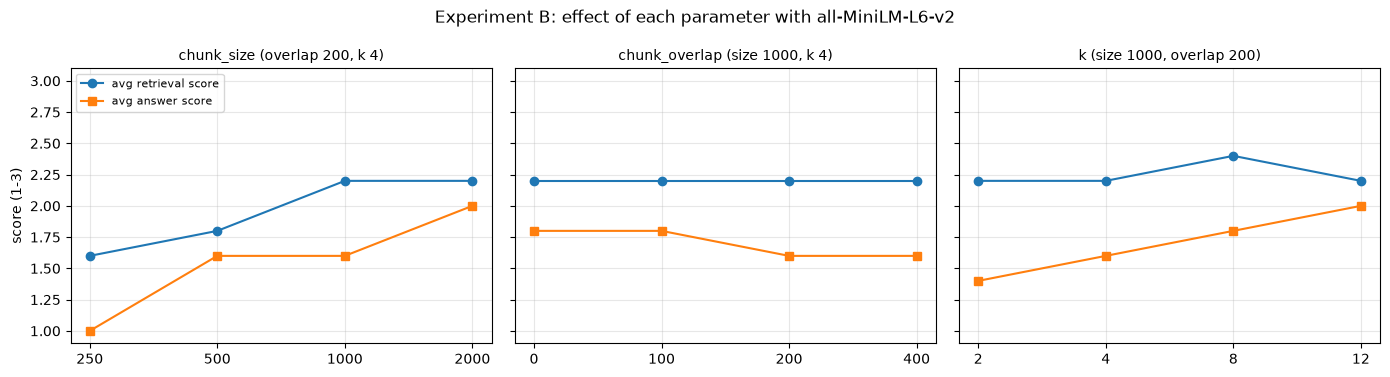

In [16]:
# Plot average scores per parameter setting
import matplotlib.pyplot as plt

groups = {
    "chunk_size (overlap 200, k 4)": ["size=250 (overlap=50)", "size=500", "default", "size=2000"],
    "chunk_overlap (size 1000, k 4)": ["overlap=0", "overlap=100", "default", "overlap=400"],
    "k (size 1000, overlap 200)": ["k=2", "default", "k=8", "k=12"],
}
xlabels = {
    "chunk_size (overlap 200, k 4)": ["250", "500", "1000", "2000"],
    "chunk_overlap (size 1000, k 4)": ["0", "100", "200", "400"],
    "k (size 1000, overlap 200)": ["2", "4", "8", "12"],
}
lookup = dict(results_b, default=default)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (title, labels) in zip(axes, groups.items()):
    ret = [lookup[l]["avg_retrieval"] for l in labels]
    ans = [lookup[l]["avg_answer"] for l in labels]
    xs = range(len(labels))
    ax.plot(xs, ret, marker="o", label="avg retrieval score")
    ax.plot(xs, ans, marker="s", label="avg answer score")
    ax.set_xticks(list(xs), xlabels[title])
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0.9, 3.1)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("score (1-3)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Experiment B: effect of each parameter with all-MiniLM-L6-v2")
fig.tight_layout()
fig.savefig("experiment_b_scores.png", dpi=150)
plt.show()

In [17]:
# Export every run (chunks + answers + scores) for the write-up
export = {}
for label, r in list(final_results.items()) + [(f"B:{l}", r) for l, r in results_b.items()]:
    export[label] = [
        {"query": d["query"], "answer": d["answer"],
         "retrieval_score": rs, "answer_score": an, "coverage": cv,
         "chunks": [{"doc": c.metadata["doc_short"], "page": c.metadata["page_number"], "text": c.page_content}
                    for c in d["retrieved_docs"]]}
        for d, rs, an, cv in zip(r["details"], r["retrieval_scores"], r["answer_scores"], r["coverage"])
    ]
with open("hw3_all_runs.json", "w", encoding="utf-8") as f:
    json.dump(export, f, indent=1, ensure_ascii=False)
print(f"Saved {len(export)} runs to hw3_all_runs.json")

Saved 11 runs to hw3_all_runs.json
